# Aula 7.2 — Exercício Guiado: SVM Linear vs. SVM RBF

Reprodução das **etapas 01–19 das páginas 46–53** do PDF da aula. Execute as células em ordem. Antes de entregar, use **Restart Kernel → Run All**.

In [1]:
# 01 - Imports
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

In [2]:
# 02 - Criar o dataset
X, y = make_circles(
    n_samples=300,
    factor=0.45,
    noise=0.10,
    random_state=42
)
print(X.shape)
print(y.shape)
print(np.unique(y, return_counts=True))

(300, 2)
(300,)
(array([0, 1]), array([150, 150]))


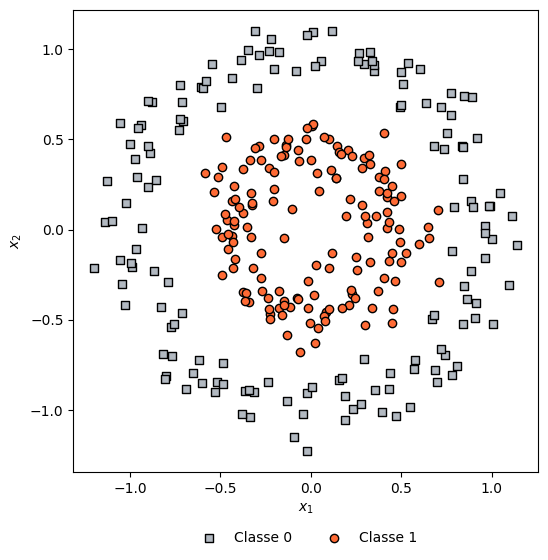

In [3]:
# 03 - Visualizar o dataset
plt.figure(figsize=(6, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1],
            c="#B2B9C1", marker="s",
            edgecolor="k", label="Classe 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1],
            c="#FF6B35", marker="o",
            edgecolor="k", label="Classe 1")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.legend(loc="upper center", ncol=2,
           bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.axis("equal")
plt.show()

In [4]:
# 04 - Separar treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)
print(X_train.shape, X_test.shape)

(225, 2) (75, 2)


In [5]:
# 05 - Construir pipeline SVM Linear
svm_linear = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="linear", C=1.0))
])

In [6]:
# 06 - Treinar SVM Linear
svm_linear.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'


In [7]:
# 07 - Prever com SVM Linear
pred_linear = svm_linear.predict(X_test)
print("Reais:    ", y_test[:15])
print("Previstos:", pred_linear[:15])

Reais:     [1 0 0 0 0 1 1 0 1 1 1 1 1 0 1]
Previstos: [1 1 0 1 0 1 0 1 1 0 0 0 0 0 1]


In [8]:
# 08 - Acurácia do SVM Linear
acc_linear = accuracy_score(y_test, pred_linear)
print(f"Acurácia (linear): {acc_linear:.3f}")

Acurácia (linear): 0.493


In [9]:
# 09 - Matriz de confusão do SVM Linear
cm_linear = confusion_matrix(y_test, pred_linear)
print(cm_linear)

[[14 24]
 [14 23]]


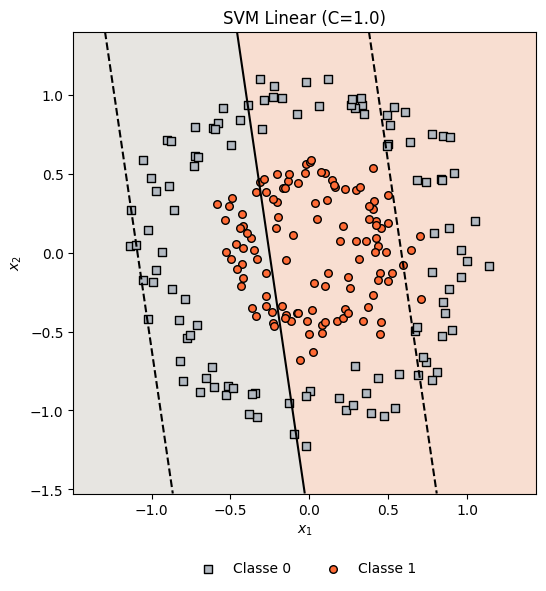

In [10]:
# 10 - Função de visualização da fronteira
def plot_decision_boundary(model, X, y, ax, title,
                           x_lim, y_lim, resolution=300):
    # 1. grade em coordenadas ORIGINAIS
    xx, yy = np.meshgrid(
        np.linspace(x_lim[0], x_lim[1], resolution),
        np.linspace(y_lim[0], y_lim[1], resolution),
    )
    grid = np.c_[xx.ravel(), yy.ravel()]

    # 2. o pipeline escalona a grade sozinho
    Z = model.predict(grid).reshape(xx.shape)
    D = model.decision_function(grid).reshape(xx.shape)

    # 3. regiões, fronteira (0) e margens (±1)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5],
                colors=["#E7E5E1", "#F8DED1"])
    ax.contour(xx, yy, D, levels=[-1, 0, 1],
               colors="k", linestyles=["--", "-", "--"])

    # 4. amostras
    ax.scatter(X[y == 0, 0], X[y == 0, 1],
               c="#B2B9C1", marker="s",
               edgecolor="k", s=30, label="Classe 0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1],
               c="#FF6B35", marker="o",
               edgecolor="k", s=30, label="Classe 1")
    ax.set_xlim(x_lim)
    ax.set_ylim(y_lim)
    ax.set_aspect("equal")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title(title)
    ax.legend(loc="upper center", ncol=3,
              frameon=False, bbox_to_anchor=(0.5, -0.12))

x_lim = (X[:, 0].min() - 0.3, X[:, 0].max() + 0.3)
y_lim = (X[:, 1].min() - 0.3, X[:, 1].max() + 0.3)
fig, ax = plt.subplots(figsize=(6, 6))
plot_decision_boundary(svm_linear, X_train, y_train,
                       ax, "SVM Linear (C=1.0)", x_lim, y_lim)
plt.show()

In [11]:
# 11 - Construir pipeline SVM RBF
svm_rbf = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

In [12]:
# 12 - Treinar SVM RBF
svm_rbf.fit(X_train, y_train)

X_train_scaled = svm_rbf.named_steps["scaler"].transform(X_train)
print("gamma efetivo:",
      1 / (X_train_scaled.shape[1] * X_train_scaled.var()))

gamma efetivo: 0.5


In [13]:
# 13 - Avaliar SVM RBF
pred_rbf = svm_rbf.predict(X_test)
acc_rbf = accuracy_score(y_test, pred_rbf)
cm_rbf = confusion_matrix(y_test, pred_rbf)
print(f"Acurácia (RBF): {acc_rbf:.3f}")
print(cm_rbf)

Acurácia (RBF): 1.000
[[38  0]
 [ 0 37]]


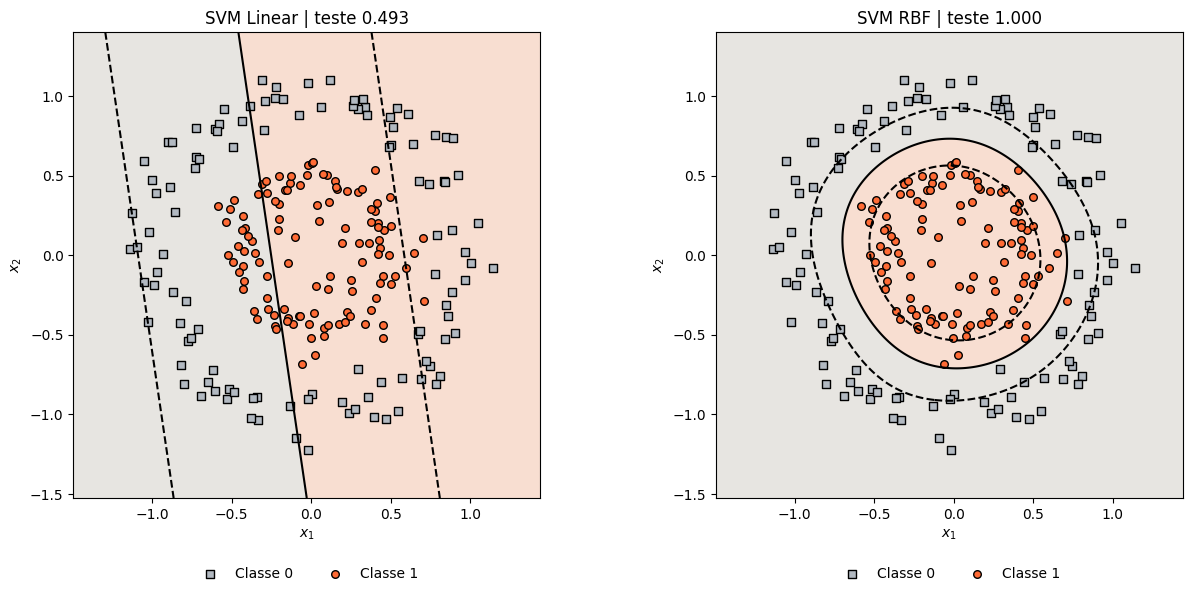

In [14]:
# 14 - Comparar as fronteiras lado a lado
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
plot_decision_boundary(svm_linear, X_train, y_train, axes[0],
                       f"SVM Linear | teste {acc_linear:.3f}", x_lim, y_lim)
plot_decision_boundary(svm_rbf, X_train, y_train, axes[1],
                       f"SVM RBF | teste {acc_rbf:.3f}", x_lim, y_lim)
plt.tight_layout()
plt.show()

Total de vetores de suporte: 44
Por classe: [22 22]
True


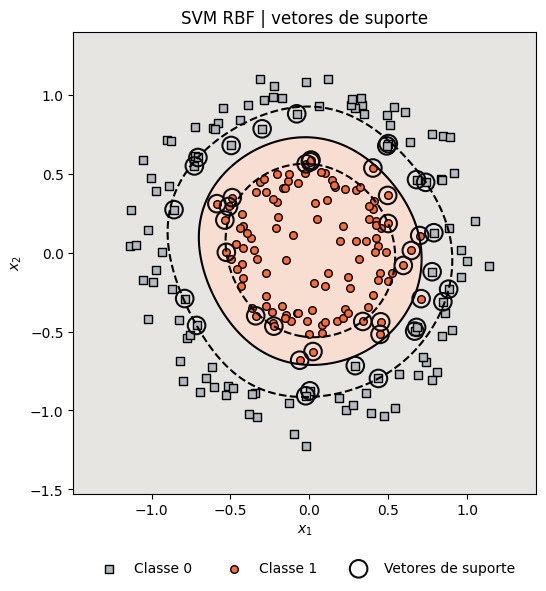

In [15]:
# 15 - Vetores de suporte nas coordenadas corretas
svc_rbf = svm_rbf.named_steps["svc"]
idx_sv = svc_rbf.support_
print("Total de vetores de suporte:", len(idx_sv))
print("Por classe:", svc_rbf.n_support_)
# índices valem para X_train (mesma ordem)
sv_original = X_train[idx_sv]
# support_vectors_ está ESCALONADO
scaler = svm_rbf.named_steps["scaler"]
sv_reconstruido = scaler.inverse_transform(
    svc_rbf.support_vectors_)
print(np.allclose(sv_original, sv_reconstruido))
fig, ax = plt.subplots(figsize=(6, 6))
plot_decision_boundary(svm_rbf, X_train, y_train, ax,
                       "SVM RBF | vetores de suporte", x_lim, y_lim)
ax.scatter(sv_original[:, 0], sv_original[:, 1],
           s=160, facecolors="none",
           edgecolors="#0C0D10", linewidths=1.5,
           label="Vetores de suporte")
ax.legend(loc="upper center", ncol=3,
          frameon=False, bbox_to_anchor=(0.5, -0.12))
plt.show()

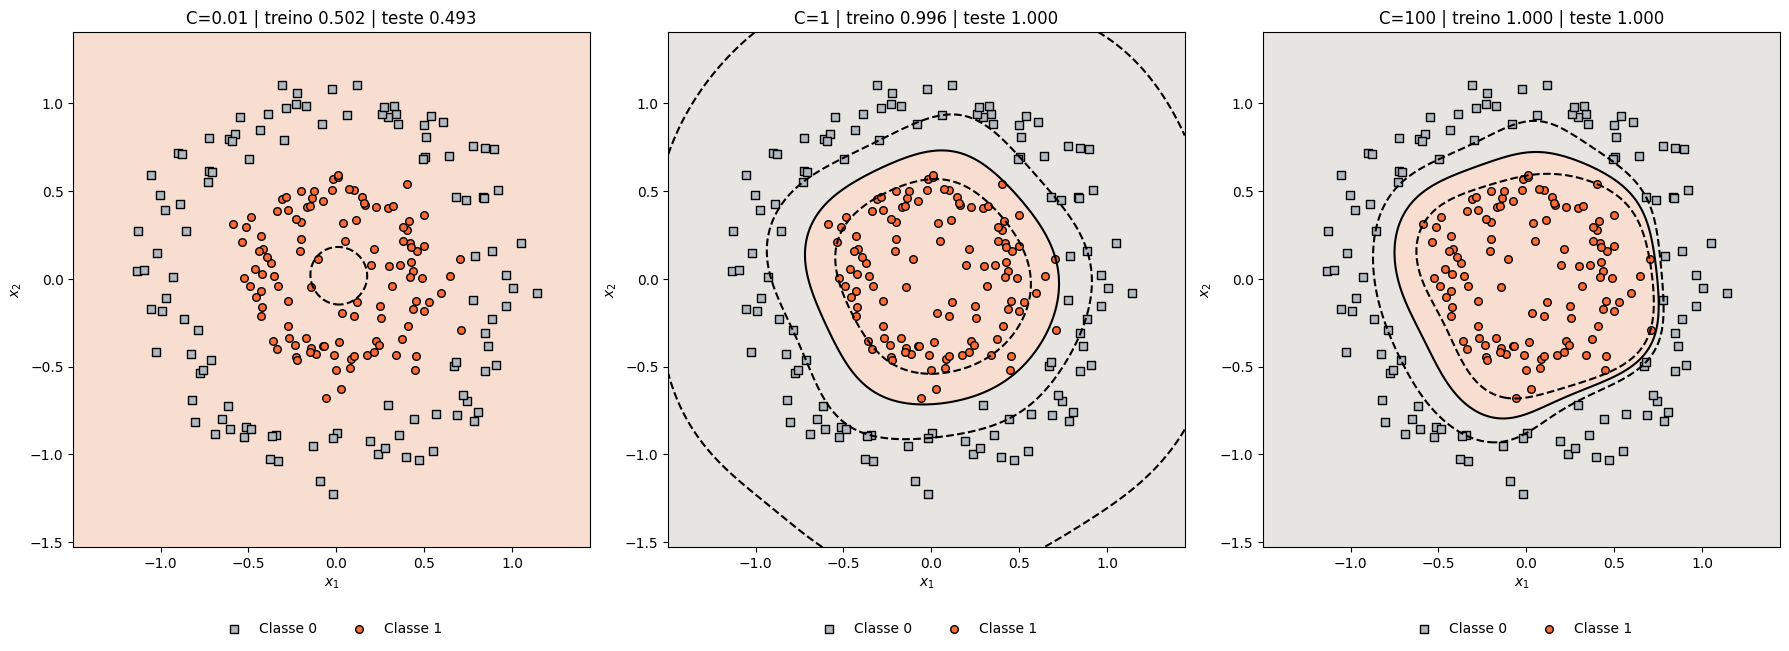

In [16]:
# 16 - Experimento com C (gamma=1.0 fixo)
valores_C = [0.01, 1, 100]
modelos_C = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, C in zip(axes, valores_C):
    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel="rbf", C=C,
                    gamma=1.0)),
    ])
    modelo.fit(X_train, y_train)
    modelos_C[C] = modelo
    acc_tr = accuracy_score(
        y_train, modelo.predict(X_train))
    acc_te = accuracy_score(
        y_test, modelo.predict(X_test))
    plot_decision_boundary(
        modelo, X_train, y_train, ax,
        f"C={C} | treino {acc_tr:.3f}"
        f" | teste {acc_te:.3f}",
        x_lim, y_lim)
plt.tight_layout()
plt.show()

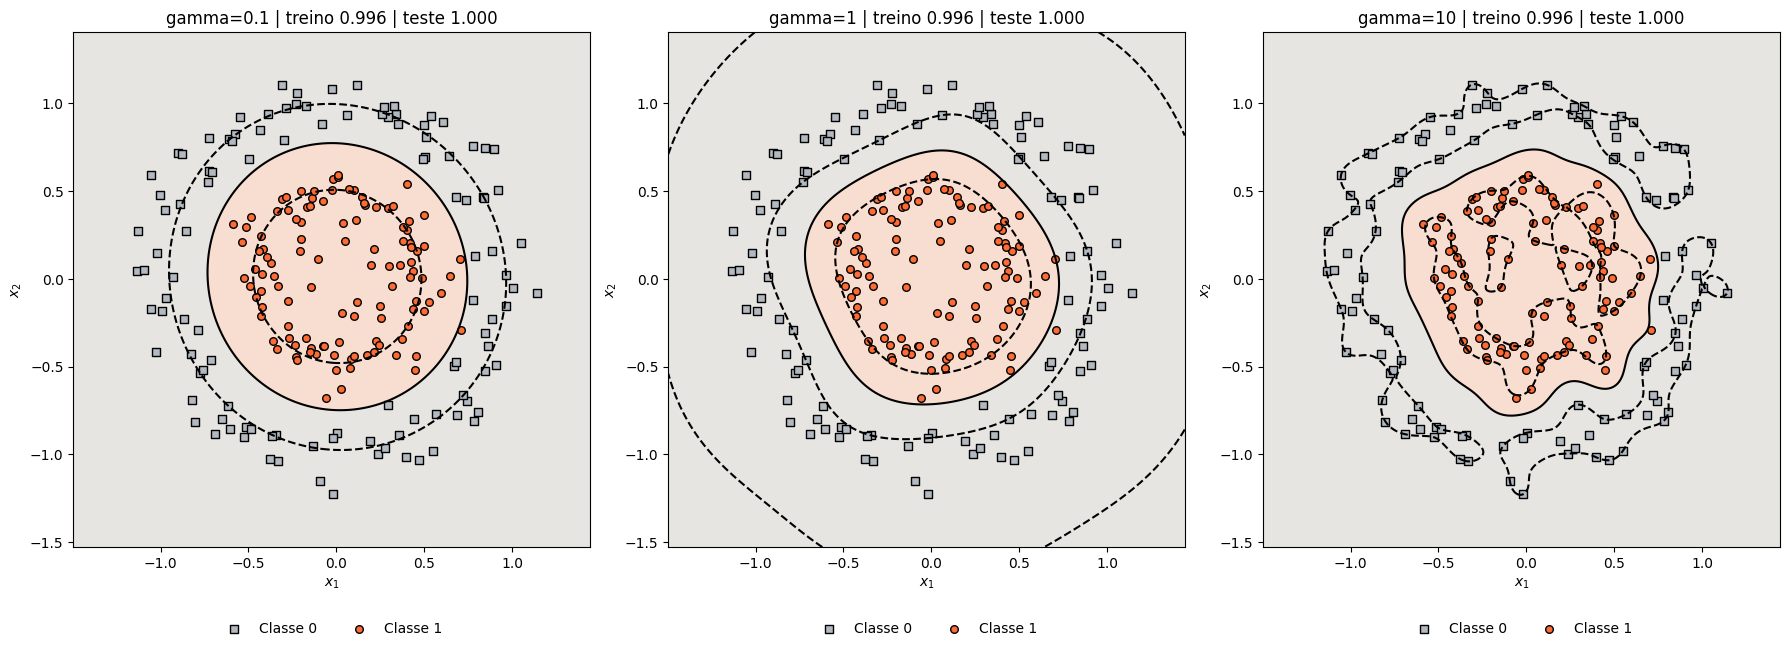

In [17]:
# 17 - Experimento com gamma (C=1.0 fixo)
valores_gamma = [0.1, 1, 10]
modelos_gamma = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, g in zip(axes, valores_gamma):
    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel="rbf", C=1.0,
                    gamma=g)),
    ])
    modelo.fit(X_train, y_train)
    modelos_gamma[g] = modelo
    acc_tr = accuracy_score(
        y_train, modelo.predict(X_train))
    acc_te = accuracy_score(
        y_test, modelo.predict(X_test))
    plot_decision_boundary(
        modelo, X_train, y_train, ax,
        f"gamma={g} | treino {acc_tr:.3f}"
        f" | teste {acc_te:.3f}",
        x_lim, y_lim)
plt.tight_layout()
plt.show()

In [18]:
# 18 - Tabela comparativa
def resumo(nome, modelo):
    svc = modelo.named_steps["svc"]
    g = "-" if svc.kernel == "linear" else svc.gamma
    return [nome, svc.kernel, svc.C, g,
            accuracy_score(y_train, modelo.predict(X_train)),
            accuracy_score(y_test, modelo.predict(X_test)),
            int(svc.n_support_.sum())]

linhas = [resumo("Linear", svm_linear),
          resumo("RBF scale", svm_rbf)]
linhas += [resumo(f"RBF C={c}", m)
           for c, m in modelos_C.items()]
linhas += [resumo(f"RBF gamma={g}", m)
           for g, m in modelos_gamma.items()]

print(f"{'Modelo':<15}{'Kernel':<8}{'C':>7}"
      f"{'gamma':>8}{'Treino':>9}{'Teste':>8}{'VS':>6}")
for nome, k, c, g, tr, te, nv in linhas:
    print(f"{nome:<15}{k:<8}{c:>7}{str(g):>8}"
          f"{tr:>9.3f}{te:>8.3f}{nv:>6}")

Modelo         Kernel        C   gamma   Treino   Teste    VS
Linear         linear      1.0       -    0.587   0.493   221
RBF scale      rbf         1.0   scale    0.991   1.000    44
RBF C=0.01     rbf        0.01     1.0    0.502   0.493   224
RBF C=1        rbf           1     1.0    0.996   1.000    41
RBF C=100      rbf         100     1.0    1.000   1.000    15
RBF gamma=0.1  rbf         1.0     0.1    0.996   1.000    97
RBF gamma=1    rbf         1.0       1    0.996   1.000    41
RBF gamma=10   rbf         1.0      10    0.996   1.000   118


## 19 — Conclusão

- **Linear:** uma reta não separa disco e anel.
- **RBF:** a similaridade por distância permite obter uma fronteira fechada.
- **C:** regula o custo das violações e o equilíbrio entre margem e ajuste.
- **Gamma:** controla o alcance da influência de cada vetor de suporte.
- **Escalonamento:** deve ficar dentro do `Pipeline`.

**Antes de entregar:** Restart Kernel → Run All.